In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rewards = np.array([[-1,0,0,10],
                   [-1,0,0,10],
                   [-1,0,0,10],
                   [-1,0,0,0]])

transitions = np.array([
    [[0.5, 0.5, 0, 0], [0.5, 0, 0.5, 0], [0, 0.5, 0, 0.5], [0, 0, 1, 0]],
    [[0, 1, 0, 0], [1, 0, 0, 0], [0, 0, 0.5, 0.5], [0, 0, 1, 0]],
    [[0, 0, 0.5, 0.5], [0, 0.5, 0, 0.5], [0, 0.5, 0, 0.5], [0, 0, 1, 0]],
    [[0, 0, 0, 1], [0, 0, 0.5, 0.5], [0, 0.5, 0, 0.5], [0.5, 0.5, 0, 0]]
])

#q-learning algorithm

In [3]:
def q_learning(transitions, rewards, gamma, alpha, epsilon, n_episodes):
    n_states, n_actions, _ = transitions.shape
    q_table = np.zeros((n_states, n_actions))

    total_rewards = []
    for episode in range(n_episodes):
        state = 0
        done = False
        total_reward = 0
        while not done:
            if np.random.rand() < epsilon:
                action = np.random.choice(n_actions)
            else:
                action = np.argmax(q_table[state])
            new_state = np.random.choice(np.arange(n_states), p = transitions[state, action] / np.sum(transitions[state, action]))
            reward = rewards[state, action]
            q_table[state, action] += alpha * (reward + gamma * np.max(q_table[new_state]) - q_table[state, action])
            state = new_state
            total_reward += reward

            if state == n_states-1:
                done = True

        total_rewards.append(total_reward)

    plt.plot(total_rewards)
    plt.xlabel('Episodes')
    plt.ylabel('Total Reward')
    plt.show()

    return q_table

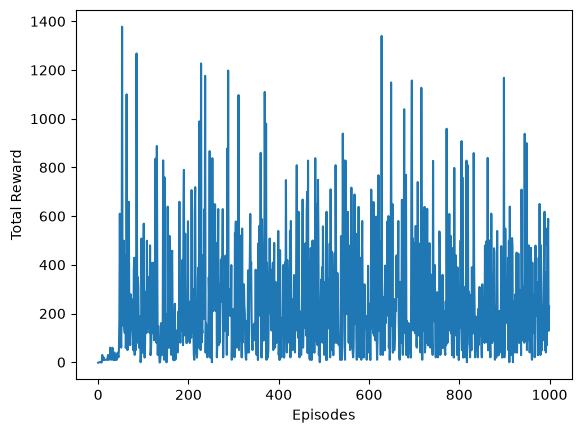

Converged Q Value:  [[ 88.99998659  89.99999876  11.2369687  100.        ]
 [ 88.77246093  90.          23.95019531 100.        ]
 [  2.75168698  54.4425355   86.06985979 100.        ]
 [  0.           0.           0.           0.        ]]


In [4]:
gamma = 0.9
alpha = 0.5
epsilon = 0.1
n_episodes = 1000

q_table = q_learning(transitions, rewards, gamma, alpha, epsilon, n_episodes)

print("Converged Q Value: ", q_table)